In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay)

In [102]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/customer_churn_20000.csv")

In [103]:
df.head()

,CustomerID,Gender,Age,SeniorCitizen,Tenure,MonthlyCharges,TotalCharges,Contract,InternetService,PaymentMethod,TechSupport,PaperlessBilling,Churn
0,CUST000001,Female,23,0,6,50.91,295.80,Month-to-month,DSL,Credit card,No,Yes,No
1,CUST000002,Female,62,0,25,43.91,1123.47,Month-to-month,DSL,Bank transfer,Yes,Yes,No
2,CUST000003,Male,55,0,52,32.81,1662.29,Month-to-month,No,Electronic check,No,No,No
3,CUST000004,Male,43,0,30,18.00,584.73,Month-to-month,No,Electronic check,Yes,Yes,No
4,CUST000005,Male,43,0,12,61.65,704.37,Two year,DSL,Bank transfer,No internet service,Yes,No


In [104]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        20000 non-null  object 
 1   Gender            20000 non-null  object 
 2   Age               20000 non-null  int64  
 3   SeniorCitizen     20000 non-null  int64  
 4   Tenure            20000 non-null  int64  
 5   MonthlyCharges    20000 non-null  float64
 6   TotalCharges      20000 non-null  float64
 7   Contract          20000 non-null  object 
 8   InternetService   20000 non-null  object 
 9   PaymentMethod     20000 non-null  object 
 10  TechSupport       20000 non-null  object 
 11  PaperlessBilling  20000 non-null  object 
 12  Churn             20000 non-null  object 
dtypes: float64(2), int64(3), object(8)
memory usage: 2.0+ MB


In [105]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'SeniorCitizen', 'Tenure',
       'MonthlyCharges', 'TotalCharges', 'Contract', 'InternetService',
       'PaymentMethod', 'TechSupport', 'PaperlessBilling', 'Churn'],
      dtype='object')

In [106]:
df.shape

(20000, 13)

In [107]:
df.isnull().sum()

CustomerID          0
Gender              0
Age                 0
SeniorCitizen       0
Tenure              0
MonthlyCharges      0
TotalCharges        0
Contract            0
InternetService     0
PaymentMethod       0
TechSupport         0
PaperlessBilling    0
Churn               0
dtype: int64

In [108]:
df.describe()

,Age,SeniorCitizen,Tenure,MonthlyCharges,TotalCharges
count,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000
mean,46.296600,0.183600,36.03540,52.549436,1897.710290
std,16.714042,0.387167,21.08243,17.463371,1330.350484
min,18.000000,0.000000,0.00000,18.000000,0.000000
25%,32.000000,0.000000,18.00000,39.697500,801.002500
50%,46.000000,0.000000,36.00000,53.950000,1672.340000
75%,61.000000,0.000000,54.00000,66.522500,2818.075000
max,75.000000,1.000000,72.00000,108.270000,6588.130000


In [109]:
df.duplicated().sum()

np.int64(0)

In [110]:
df.isnull().sum()

CustomerID          0
Gender              0
Age                 0
SeniorCitizen       0
Tenure              0
MonthlyCharges      0
TotalCharges        0
Contract            0
InternetService     0
PaymentMethod       0
TechSupport         0
PaperlessBilling    0
Churn               0
dtype: int64

In [121]:
X = df.drop("Churn", axis=1)
y = df["Churn"].map({
    "No": 0,
    "Yes": 1})

In [122]:
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
print(numerical_cols)
print(categorical_cols)

['Age', 'SeniorCitizen', 'Tenure', 'MonthlyCharges', 'TotalCharges']
['Gender', 'Contract', 'InternetService', 'PaymentMethod', 'TechSupport', 'PaperlessBilling']


In [138]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print(X_train.shape)
print(X_test.shape)

(16000, 11)
(4000, 11)


In [124]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

In [125]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [126]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ])

In [127]:
scale_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum())
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1)

In [128]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", xgb_model)
])

In [130]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Gender','Age','SeniorCitizen',...,'PaymentMethod','TechSupport', 'PaperlessBilling']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='

In [131]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [132]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.69925
Precision: 0.25625920471281294
Recall: 0.6432532347504621
F1 Score: 0.3665086887835703
ROC AUC: 0.737944198717589


In [133]:
print(classification_report(y_test,y_pred,target_names=["No Churn", "Churn"]))

              precision    recall  f1-score   support

    No Churn       0.93      0.71      0.80      3459
       Churn       0.26      0.64      0.37       541

    accuracy                           0.70      4000
   macro avg       0.59      0.68      0.58      4000
weighted avg       0.84      0.70      0.74      4000



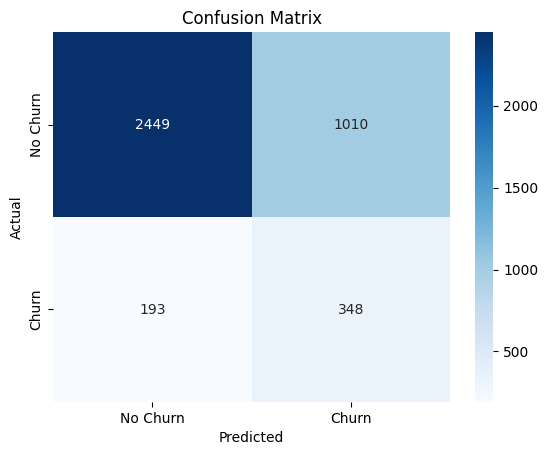

In [134]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

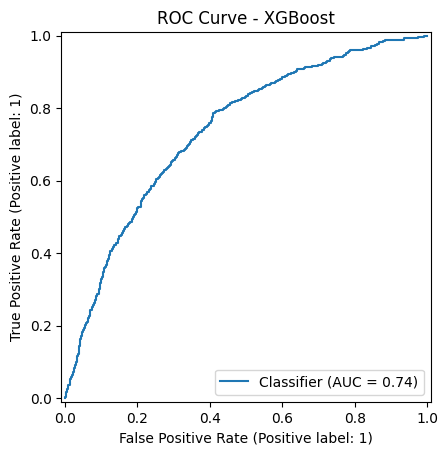

In [135]:
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC Curve - XGBoost")
plt.show()

In [136]:
new_customer = pd.DataFrame([{
    "Gender": "Male",
    "Age": 35,
    "SeniorCitizen": 0,
    "Tenure": 5,
    "MonthlyCharges": 85.50,
    "TotalCharges": 427.50,
    "Contract": "Month-to-month",
    "InternetService": "Fiber optic",
    "PaymentMethod": "Electronic check",
    "TechSupport": "No",
    "PaperlessBilling": "Yes"
}])
prediction = model.predict(new_customer)[0]
probability = model.predict_proba(new_customer)[0][1]
print("Prediction:", "Churn" if prediction == 1 else "No Churn")
print("Churn Probability:", round(probability * 100, 2), "%")

Prediction: Churn
Churn Probability: 84.73 %


In [137]:
joblib.dump(model, "customer_churn_xgboost.pkl")
print("Model saved successfully!")

Model saved successfully!
